<a href="https://colab.research.google.com/github/HeyWinTomsy/MN/blob/main/%D0%9B%D0%A08_%D0%90%D0%BD%D1%82%D1%80%D0%BE%D0%BF%D0%BE%D0%B2_%D0%A4%D0%86%D0%A23_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 8
## Методи кластеризації: K-Means, метод ліктя, коефіцієнт силуета та PCA

**Мета:** навчитися застосовувати алгоритм K-Means, добирати кількість кластерів за допомогою методу ліктя та коефіцієнта силуета; дослідити використання PCA. Додатково — порівняти моделі класифікації на наборі даних про студентів (цей етап збережено з початкової роботи).

**Середовище:** Google Colab або Jupyter Notebook із Python. Для завдання 2 потрібно завантажити набір даних з кагл https://www.kaggle.com/datasets/rabieelkharoua/students-performance-dataset?select=Student_performance_data+_.csv.

**Виконання:** запускайте комірки послідовно, зверху вниз.

## Завдання 1. Кластеризація набору даних Iris

**1.1. Імпорт бібліотек.** Імпортуйте `matplotlib`, `pandas`, `seaborn`, `load_iris`, `KMeans`, `silhouette_score` і `StandardScaler`.

In [ ]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_iris
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

**1.2. Завантаження Iris.** Завантажте Iris та виведіть перші п’ять рядків таблиці з назвами ознак.

In [ ]:
iris = load_iris()

df = pd.DataFrame(iris.data, columns=iris.feature_names)

print("Перші 5 рядків датасету:")
display(df.head())

Перші 5 рядків датасету:


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


**1.3. Масштабування та метод ліктя.** Стандартизуйте дані та за допомогою методу ліктя визначте оптимальну кількість кластерів

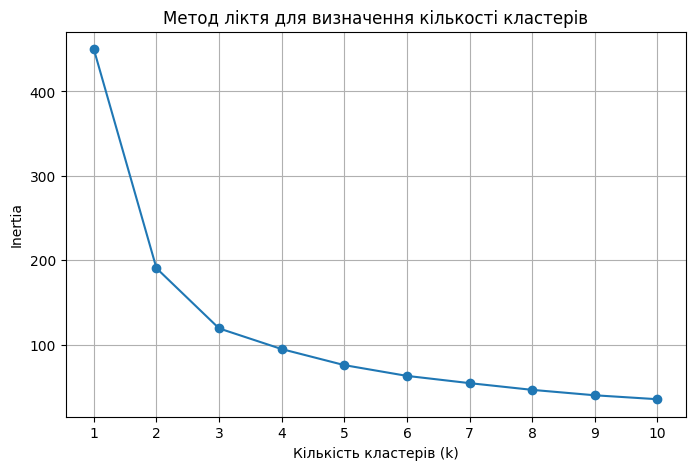

In [ ]:
X = df.iloc[:, :3]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

inertia = []

for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia, marker='o')
plt.title('Метод ліктя для визначення кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Inertia')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

**1.4. Метод силуетів.** Для тих самих трьох ознак Iris обчисліть середній коефіцієнт силуета для 2–10 кластерів і побудуйте графік.

Кількість кластерів: 2, Коефіцієнт силуета: 0.5525
Кількість кластерів: 3, Коефіцієнт силуета: 0.4594
Кількість кластерів: 4, Коефіцієнт силуета: 0.4057
Кількість кластерів: 5, Коефіцієнт силуета: 0.3755
Кількість кластерів: 6, Коефіцієнт силуета: 0.3772
Кількість кластерів: 7, Коефіцієнт силуета: 0.3628
Кількість кластерів: 8, Коефіцієнт силуета: 0.3814
Кількість кластерів: 9, Коефіцієнт силуета: 0.3749
Кількість кластерів: 10, Коефіцієнт силуета: 0.3791


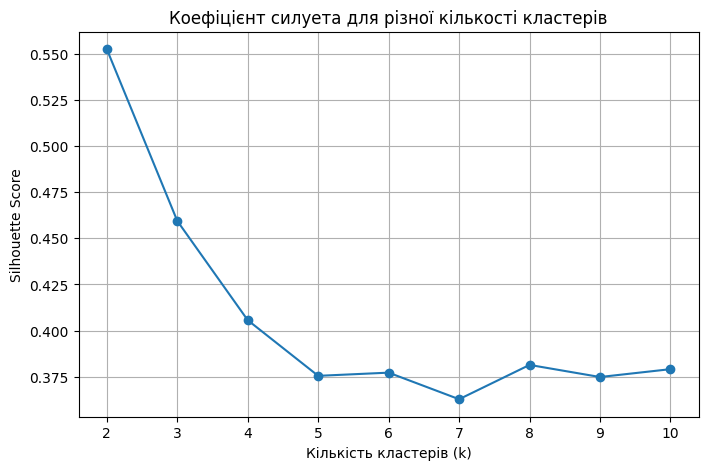

In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)
    silhouette_scores.append(score)

    print(f"Кількість кластерів: {k}, "
          f"Коефіцієнт силуета: {score:.4f}")

plt.figure(figsize=(8, 5))
plt.plot(range(2, 11), silhouette_scores, marker='o')

plt.title('Коефіцієнт силуета для різної кількості кластерів')
plt.xlabel('Кількість кластерів (k)')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

**1.5. Фінальна кластеризація та візуалізація.** Побудуйте K-Means для `n_clusters=2`  На площині покажіть перші дві з них та відповідні координати центрів. Це **двовимірне відображення результату кластеризації за трьома ознаками**.

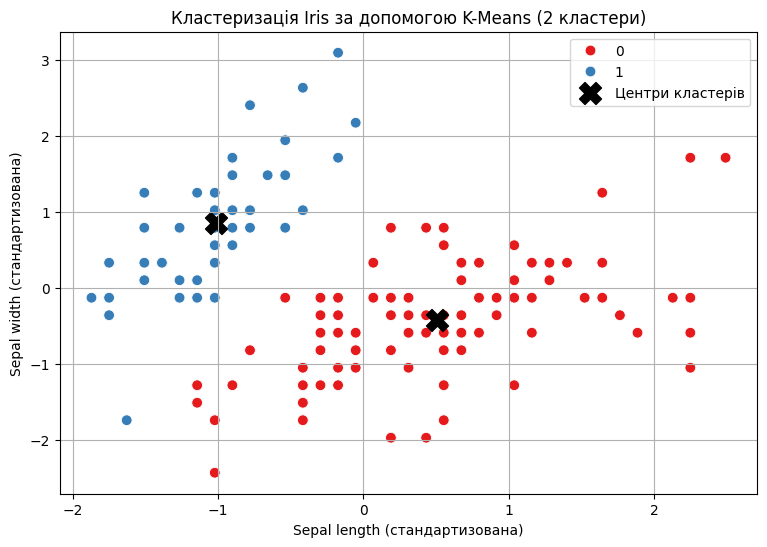

Координати центрів кластерів:
[[ 0.50728948 -0.42663134]
 [-1.01457897  0.85326268]]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),Cluster
0,5.1,3.5,1.4,0.2,1
1,4.9,3.0,1.4,0.2,1
2,4.7,3.2,1.3,0.2,1
3,4.6,3.1,1.5,0.2,1
4,5.0,3.6,1.4,0.2,1


In [ ]:
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

clusters = kmeans_final.fit_predict(X_scaled)

df['Cluster'] = clusters

centers = kmeans_final.cluster_centers_

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_scaled[:, 0],
    y=X_scaled[:, 1],
    hue=clusters,
    palette='Set1',
    s=60
)

plt.scatter(
    centers[:, 0],
    centers[:, 1],
    marker='X',
    s=250,
    color='black',
    label='Центри кластерів'
)

plt.title('Кластеризація Iris за допомогою K-Means (2 кластери)')
plt.xlabel('Sepal length (стандартизована)')
plt.ylabel('Sepal width (стандартизована)')
plt.legend()
plt.grid(True)
plt.show()

print("Координати центрів кластерів:")
print(centers[:, :2])

display(df.head())

**Короткий висновок до завдання 1:** порівняйте результати методу ліктя й методу силуетів. Поясніть, чому обрано два кластери та чи збігається такий вибір з отриманими графіками.

## Завдання 2. Дослідження даних студентів

Спочатку порівняйте три класифікатори (як у початковій лабораторній роботі), а потім виконайте кластеризацію. **Класифікація та кластеризація — різні задачі:** у класифікації використовується цільова ознака `GradeClass`, а в кластеризації — ні.

**2.1. Імпорт бібліотек для класифікації.** Імпортуйте засоби для поділу даних, добору параметрів, класифікації та оцінювання моделей.

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
import os

from google.colab import files
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA
from kneed import KneeLocator

**2.2. Завантаження файлу.** Помістіть `Student_data.csv` до робочої папки або завантажте його через Colab. Файл містить дані з Вашої початкової роботи.

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("rabieelkharoua/students-performance-dataset")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'students-performance-dataset' dataset.
Path to dataset files: /kaggle/input/students-performance-dataset


**2.3. Перегляд даних.** Прочитайте CSV у DataFrame і перегляньте вміст.

In [ ]:
# Вивід даних з файлу
df = pd.read_csv(os.path.join(path,'Student_performance_data _.csv'))
df.head()

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
0,1001,17,1,0,2,19.833723,7,1,2,0,0,1,0,2.929196,2.0
1,1002,18,0,0,1,15.408756,0,0,1,0,0,0,0,3.042915,1.0
2,1003,15,0,2,3,4.210570,26,0,2,0,0,0,0,0.112602,4.0
3,1004,17,1,0,3,10.028829,14,0,3,1,0,0,0,2.054218,3.0
4,1005,17,1,0,2,4.672495,17,1,3,0,0,0,0,1.288061,4.0


**2.4. Назви стовпців.** Виведіть назви всіх стовпців.

In [ ]:
print("Назви стовпців:")
print(df.columns.tolist())

Назви стовпців:
['StudentID', 'Age', 'Gender', 'Ethnicity', 'ParentalEducation', 'StudyTimeWeekly', 'Absences', 'Tutoring', 'ParentalSupport', 'Extracurricular', 'Sports', 'Music', 'Volunteering', 'GPA', 'GradeClass']


**2.5. Структура таблиці.** Перегляньте типи стовпців і кількість непорожніх значень.

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2392 entries, 0 to 2391
Data columns (total 15 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   StudentID          2392 non-null   int64  
 1   Age                2392 non-null   int64  
 2   Gender             2392 non-null   int64  
 3   Ethnicity          2392 non-null   int64  
 4   ParentalEducation  2392 non-null   int64  
 5   StudyTimeWeekly    2392 non-null   float64
 6   Absences           2392 non-null   int64  
 7   Tutoring           2392 non-null   int64  
 8   ParentalSupport    2392 non-null   int64  
 9   Extracurricular    2392 non-null   int64  
 10  Sports             2392 non-null   int64  
 11  Music              2392 non-null   int64  
 12  Volunteering       2392 non-null   int64  
 13  GPA                2392 non-null   float64
 14  GradeClass         2392 non-null   float64
dtypes: float64(3), int64(12)
memory usage: 280.4 KB


**2.6. Пропущені значення.** Перевірте, чи містить набір даних пропущені значення.

In [ ]:
print("Кількість пропущених значень у кожному стовпці:")
print(df.isnull().sum())

print("\nЗагальна кількість пропущених значень:")
print(df.isnull().sum().sum())

Кількість пропущених значень у кожному стовпці:
StudentID            0
Age                  0
Gender               0
Ethnicity            0
ParentalEducation    0
StudyTimeWeekly      0
Absences             0
Tutoring             0
ParentalSupport      0
Extracurricular      0
Sports               0
Music                0
Volunteering         0
GPA                  0
GradeClass           0
dtype: int64

Загальна кількість пропущених значень:
0


**2.7. Дублікати.** Обчисліть кількість дублікатів.

In [ ]:
duplicates = df.duplicated().sum()

print("Кількість дублікатів:", duplicates)

Кількість дублікатів: 0


**2.8. Описова статистика.** Виведіть основні описові статистики.

In [ ]:
display(df.describe())

,StudentID,Age,Gender,Ethnicity,ParentalEducation,StudyTimeWeekly,Absences,Tutoring,ParentalSupport,Extracurricular,Sports,Music,Volunteering,GPA,GradeClass
count,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000,2392.000000
mean,2196.500000,16.468645,0.510870,0.877508,1.746237,9.771992,14.541388,0.301421,2.122074,0.383361,0.303512,0.196906,0.157191,1.906186,2.983696
std,690.655244,1.123798,0.499986,1.028476,1.000411,5.652774,8.467417,0.458971,1.122813,0.486307,0.459870,0.397744,0.364057,0.915156,1.233908
min,1001.000000,15.000000,0.000000,0.000000,0.000000,0.001057,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,1598.750000,15.000000,0.000000,0.000000,1.000000,5.043079,7.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.174803,2.000000
50%,2196.500000,16.000000,1.000000,0.000000,2.000000,9.705363,15.000000,0.000000,2.000000,0.000000,0.000000,0.000000,0.000000,1.893393,4.000000
75%,2794.250000,17.000000,1.000000,2.000000,2.000000,14.408410,22.000000,1.000000,3.000000,1.000000,1.000000,0.000000,0.000000,2.622216,4.000000
max,3392.000000,18.000000,1.000000,3.000000,4.000000,19.978094,29.000000,1.000000,4.000000,1.000000,1.000000,1.000000,1.000000,4.000000,4.000000


**2.9. Підготовка даних для класифікації.** Сформуйте `X` та `y`, прибравши з ознак цільову змінну `GradeClass` і службовий ідентифікатор `StudentID`. Поділіть дані у співвідношенні 80/20 та стандартизуйте ознаки.

In [ ]:
X = df.drop(columns=['GradeClass', 'StudentID'])

y = df['GradeClass']

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Розмір навчальної вибірки:", X_train.shape)
print("Розмір тестової вибірки:", X_test.shape)

Розмір навчальної вибірки: (1913, 13)
Розмір тестової вибірки: (479, 13)


### 2.10. Класифікація: Random Forest

**Модель Random Forest.** Здійсніть добір гіперпараметрів `GridSearchCV` (5 згорток), виведіть найкращі параметри, середню CV-точність і тестову accuracy. Пошук може тривати довше через велику сітку параметрів.

In [ ]:
rf_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', RandomForestClassifier(random_state=42))
])

rf_params = {
    'classifier__n_estimators': [100, 200],
    'classifier__max_depth': [None, 10, 20],
    'classifier__min_samples_split': [2, 5],
    'classifier__min_samples_leaf': [1, 2]
}

rf_grid = GridSearchCV(
    rf_pipeline,
    rf_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

rf_grid.fit(X_train, y_train)

print("Найкращі параметри Random Forest:")
print(rf_grid.best_params_)

print("\nСередня CV-точність:")
print(rf_grid.best_score_)

rf_pred = rf_grid.predict(X_test)

rf_accuracy = accuracy_score(y_test, rf_pred)

print("\nТестова accuracy Random Forest:")
print(rf_accuracy)

Fitting 5 folds for each of 24 candidates, totalling 120 fits
Найкращі параметри Random Forest:
{'classifier__max_depth': 10, 'classifier__min_samples_leaf': 1, 'classifier__min_samples_split': 2, 'classifier__n_estimators': 200}

Середня CV-точність:
0.9210709061829316

Тестова accuracy Random Forest:
0.9102296450939458


### 2.11. Класифікація: Logistic Regression

**Модель Logistic Regression.** Застосуйте `GridSearchCV` до логістичної регресії. Для багатокласової задачі використайте `saga` — `liblinear` у нових версіях sklearn не підтримує багатокласову класифікацію без додаткової обгортки.

In [ ]:
lr_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(
        solver='saga',
        max_iter=5000,
        random_state=42
    ))
])

lr_params = {
    'classifier__C': [0.01, 0.1, 1, 10, 100],
    'classifier__penalty': ['l1', 'l2']
}

lr_grid = GridSearchCV(
    lr_pipeline,
    lr_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

lr_grid.fit(X_train, y_train)

print("Найкращі параметри Logistic Regression:")
print(lr_grid.best_params_)

print("\nСередня CV-точність:")
print(lr_grid.best_score_)

lr_pred = lr_grid.predict(X_test)

lr_accuracy = accuracy_score(y_test, lr_pred)

print("\nТестова accuracy Logistic Regression:")
print(lr_accuracy)

Fitting 5 folds for each of 10 candidates, totalling 50 fits
Найкращі параметри Logistic Regression:
{'classifier__C': 0.1, 'classifier__penalty': 'l1'}

Середня CV-точність:
0.8024100173608737

Тестова accuracy Logistic Regression:
0.8183716075156576


### 2.12. Класифікація: Support Vector Machine

**Модель SVM.** Виконайте підбір параметрів SVM та обчисліть CV-точність і тестову accuracy.

In [ ]:
svm_pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', SVC())
])

svm_params = {
    'classifier__C': [0.1, 1, 10, 100],
    'classifier__kernel': ['linear', 'rbf'],
    'classifier__gamma': ['scale', 'auto']
}

svm_grid = GridSearchCV(
    svm_pipeline,
    svm_params,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)

svm_grid.fit(X_train, y_train)

print("Найкращі параметри SVM:")
print(svm_grid.best_params_)

print("\nСередня CV-точність:")
print(svm_grid.best_score_)

svm_pred = svm_grid.predict(X_test)

svm_accuracy = accuracy_score(y_test, svm_pred)

print("\nТестова accuracy SVM:")
print(svm_accuracy)

Fitting 5 folds for each of 16 candidates, totalling 80 fits
Найкращі параметри SVM:
{'classifier__C': 100, 'classifier__gamma': 'scale', 'classifier__kernel': 'linear'}

Середня CV-точність:
0.8551993766489414

Тестова accuracy SVM:
0.8496868475991649


### 2.13. Порівняння результатів

**Порівняння моделей.** Порівняйте тестову точність трьох моделей. Оберіть модель **за найкращою CV-точністю**, а звіт `classification_report` виведіть один раз на тестових даних.

,Model,CV Accuracy,Test Accuracy
0,Random Forest,0.921071,0.910230
1,SVM,0.855199,0.849687
2,Logistic Regression,0.802410,0.818372


Найкраща модель за CV Accuracy: Random Forest


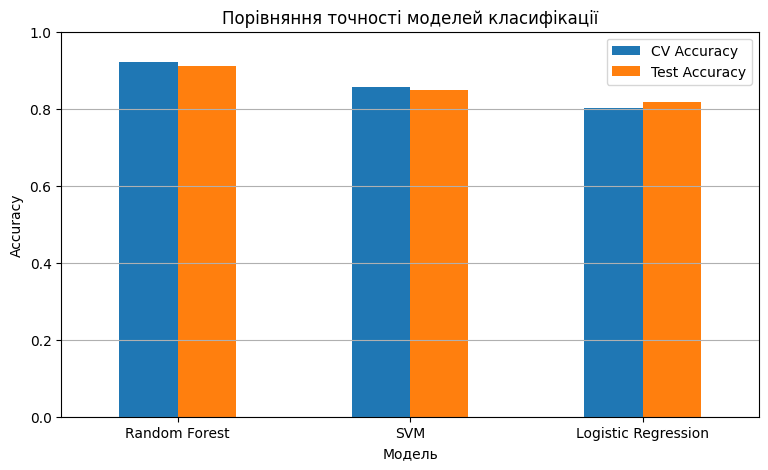


Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      0.29      0.44        21
         1.0       0.82      0.85      0.84        54
         2.0       0.89      0.95      0.92        78
         3.0       0.89      0.89      0.89        83
         4.0       0.94      0.97      0.96       243

    accuracy                           0.91       479
   macro avg       0.91      0.79      0.81       479
weighted avg       0.91      0.91      0.90       479



In [ ]:
results = pd.DataFrame({
    'Model': [
        'Random Forest',
        'Logistic Regression',
        'SVM'
    ],
    'CV Accuracy': [
        rf_grid.best_score_,
        lr_grid.best_score_,
        svm_grid.best_score_
    ],
    'Test Accuracy': [
        rf_accuracy,
        lr_accuracy,
        svm_accuracy
    ]
})

results = results.sort_values(
    by='CV Accuracy',
    ascending=False
).reset_index(drop=True)

display(results)

best_model_name = results.loc[0, 'Model']

best_models = {
    'Random Forest': (rf_grid, rf_pred),
    'Logistic Regression': (lr_grid, lr_pred),
    'SVM': (svm_grid, svm_pred)
}

best_model, best_predictions = best_models[best_model_name]

print("Найкраща модель за CV Accuracy:", best_model_name)

results.set_index('Model')[['CV Accuracy', 'Test Accuracy']].plot(
    kind='bar',
    figsize=(9, 5)
)

plt.title('Порівняння точності моделей класифікації')
plt.ylabel('Accuracy')
plt.xlabel('Модель')
plt.xticks(rotation=0)
plt.ylim(0, 1)
plt.grid(axis='y')
plt.show()

print("\nClassification Report:")
print(classification_report(
    y_test,
    best_predictions,
    zero_division=0
))

### 2.14. Кластеризація даних студентів: метод ліктя

**Метод ліктя для студентів.** Для кластеризації використайте чотири числові ознаки `Age`, `StudyTimeWeekly`, `Absences`, `GPA`. Стандартизуйте їх і побудуйте графік WCSS для 1–10 кластерів.

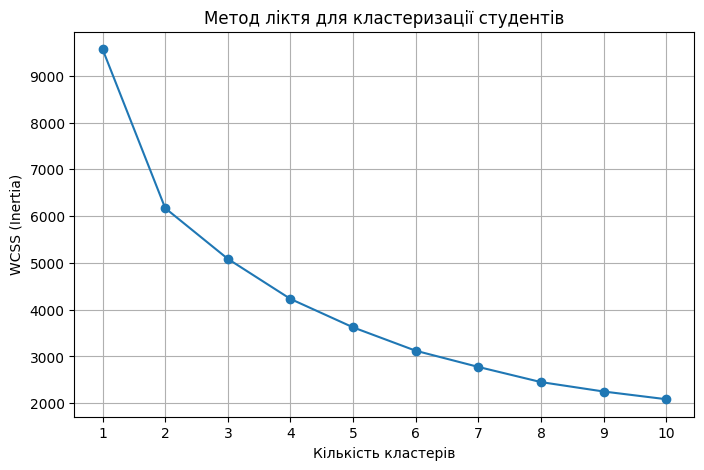

In [ ]:
cluster_features = [
    'Age',
    'StudyTimeWeekly',
    'Absences',
    'GPA'
]

X_cluster = df[cluster_features]

scaler_cluster = StandardScaler()
X_cluster_scaled = scaler_cluster.fit_transform(X_cluster)

wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_cluster_scaled)

    wcss.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 11),
    wcss,
    marker='o'
)

plt.title('Метод ліктя для кластеризації студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('WCSS (Inertia)')
plt.xticks(range(1, 11))
plt.grid(True)
plt.show()

### 2.15. Кластеризація даних студентів: метод силуетів

**Метод силуетів для студентів.** Для тих самих чотирьох ознак побудуйте графік коефіцієнта силуета для 2–10 кластерів.

Кількість кластерів: 2, Silhouette Score: 0.3080
Кількість кластерів: 3, Silhouette Score: 0.2702
Кількість кластерів: 4, Silhouette Score: 0.2580
Кількість кластерів: 5, Silhouette Score: 0.2645
Кількість кластерів: 6, Silhouette Score: 0.2689
Кількість кластерів: 7, Silhouette Score: 0.2692
Кількість кластерів: 8, Silhouette Score: 0.2712
Кількість кластерів: 9, Silhouette Score: 0.2732
Кількість кластерів: 10, Silhouette Score: 0.2725


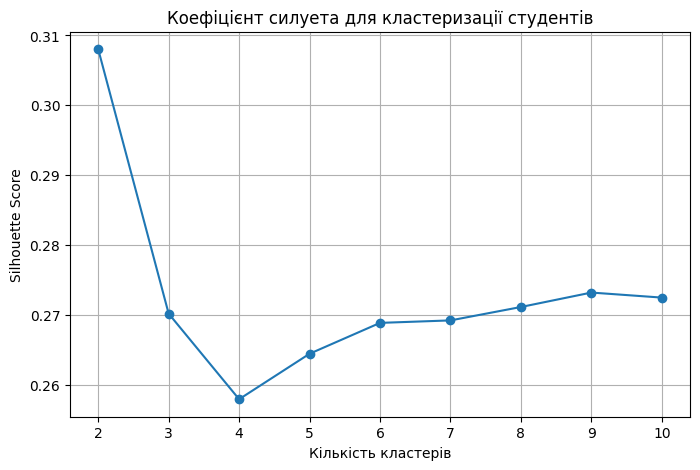


Найкраща кількість кластерів за силуетом: 2
Найкращий Silhouette Score: 0.3080330896916071


In [ ]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_cluster_scaled)

    score = silhouette_score(
        X_cluster_scaled,
        labels
    )

    silhouette_scores.append(score)

    print(
        f"Кількість кластерів: {k}, "
        f"Silhouette Score: {score:.4f}"
    )

plt.figure(figsize=(8, 5))

plt.plot(
    range(2, 11),
    silhouette_scores,
    marker='o'
)

plt.title('Коефіцієнт силуета для кластеризації студентів')
plt.xlabel('Кількість кластерів')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(True)
plt.show()

best_silhouette_k = range(2, 11)[
    silhouette_scores.index(max(silhouette_scores))
]

print("\nНайкраща кількість кластерів за силуетом:",
      best_silhouette_k)

print("Найкращий Silhouette Score:",
      max(silhouette_scores))

### 2.16. Додатковий підхід: PCA та автоматичне визначення точки ліктя

Тут використовується **інший набір ознак**: усі стовпці, крім `StudentID` та `GradeClass`. Після PCA кластеризацію проведемо за вибраними головними компонентами.

**Установлення додаткових пакетів.** За потреби встановіть `kneed` і `yellowbrick` у середовищі ноутбука.

In [ ]:
!pip install -q kneed yellowbrick

**Імпорт PCA і KneeLocator.** Імпортуйте `PCA`, `KneeLocator` та `numpy`.

In [ ]:
X_pca = df.drop(
    columns=['StudentID', 'GradeClass']
)

print("Типи даних:")
print(X_pca.dtypes)

print("\nРозмір набору даних:")
print(X_pca.shape)

print("\nПропущені значення:")
print(X_pca.isnull().sum().sum())

Типи даних:
Age                    int64
Gender                 int64
Ethnicity              int64
ParentalEducation      int64
StudyTimeWeekly      float64
Absences               int64
Tutoring               int64
ParentalSupport        int64
Extracurricular        int64
Sports                 int64
Music                  int64
Volunteering           int64
GPA                  float64
dtype: object

Розмір набору даних:
(2392, 13)

Пропущені значення:
0


**Підготовка всіх ознак.** Приберіть `StudentID` і `GradeClass`, залишивши ознаки для PCA.

Частка поясненої дисперсії компонент:
Компонента 0: 0.1525
Компонента 1: 0.0861
Компонента 2: 0.0827
Компонента 3: 0.0807
Компонента 4: 0.0786
Компонента 5: 0.0779
Компонента 6: 0.0763
Компонента 7: 0.0760
Компонента 8: 0.0744
Компонента 9: 0.0738
Компонента 10: 0.0717
Компонента 11: 0.0675
Компонента 12: 0.0018


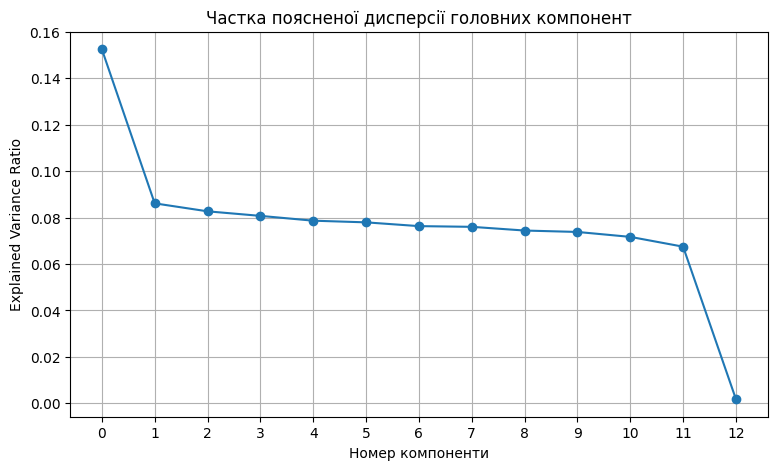

In [ ]:
scaler_pca = StandardScaler()

X_pca_scaled = scaler_pca.fit_transform(X_pca)

pca = PCA()

X_pca_transformed = pca.fit_transform(X_pca_scaled)

explained_variance = pca.explained_variance_ratio_

print("Частка поясненої дисперсії компонент:")

for i, variance in enumerate(explained_variance):
    print(f"Компонента {i}: {variance:.4f}")

plt.figure(figsize=(9, 5))

plt.plot(
    range(len(explained_variance)),
    explained_variance,
    marker='o'
)

plt.title('Частка поясненої дисперсії головних компонент')
plt.xlabel('Номер компоненти')
plt.ylabel('Explained Variance Ratio')
plt.xticks(range(len(explained_variance)))
plt.grid(True)
plt.show()

**Модель PCA.** Стандартизуйте ознаки, навчіть PCA та знайдіть частку поясненої дисперсії кожної компоненти.

Точка перегину: 1


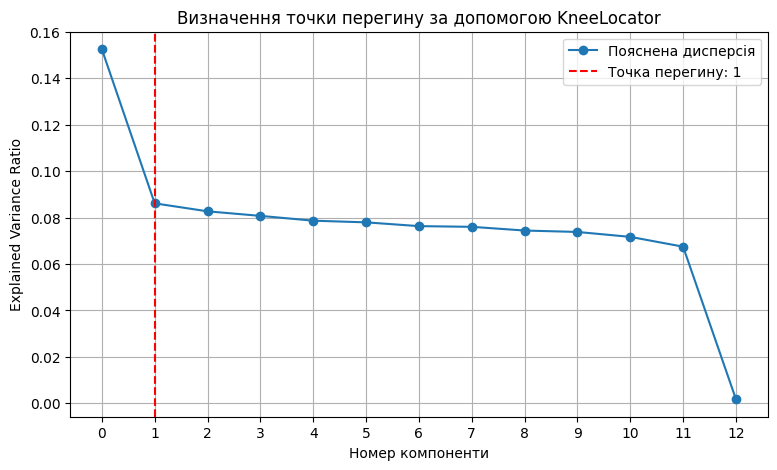

In [ ]:
components = np.arange(len(explained_variance))

knee_locator = KneeLocator(
    components,
    explained_variance,
    curve='convex',
    direction='decreasing'
)

knee_point = knee_locator.knee

print("Точка перегину:", knee_point)

plt.figure(figsize=(9, 5))

plt.plot(
    components,
    explained_variance,
    marker='o',
    label='Пояснена дисперсія'
)

if knee_point is not None:
    plt.axvline(
        x=knee_point,
        color='red',
        linestyle='--',
        label=f'Точка перегину: {knee_point}'
    )

plt.title('Визначення точки перегину за допомогою KneeLocator')
plt.xlabel('Номер компоненти')
plt.ylabel('Explained Variance Ratio')
plt.xticks(components)
plt.legend()
plt.grid(True)
plt.show()

**Визначення кількості компонент.** Застосуйте `KneeLocator` до часток поясненої дисперсії. У підписі графіка вказуйте номер компоненти без додавання одиниці.

Обрана кількість компонент: 2
Кумулятивна пояснена дисперсія: 0.23858271308863227


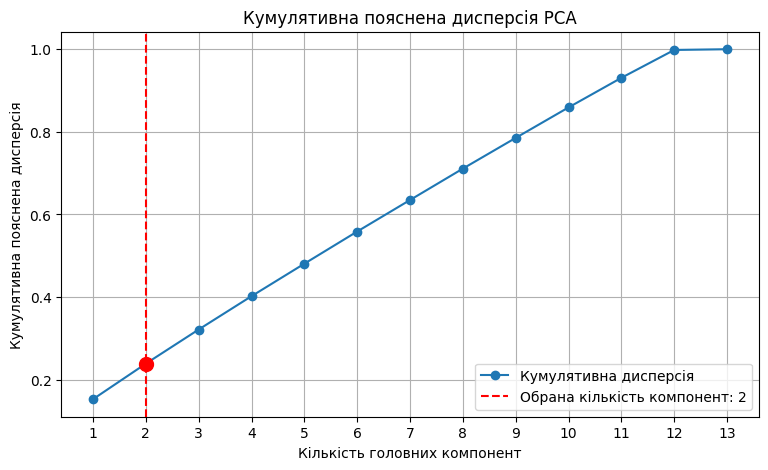


Фактична пояснена дисперсія: 0.2386


In [ ]:
cumulative_variance = np.cumsum(explained_variance)

if knee_point is not None:
    n_components_opt = knee_point + 1
else:
    n_components_opt = np.argmax(
        cumulative_variance >= 0.90
    ) + 1

print("Обрана кількість компонент:",
      n_components_opt)

print("Кумулятивна пояснена дисперсія:",
      cumulative_variance[n_components_opt - 1])

plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(cumulative_variance) + 1),
    cumulative_variance,
    marker='o',
    label='Кумулятивна дисперсія'
)

plt.axvline(
    x=n_components_opt,
    color='red',
    linestyle='--',
    label=f'Обрана кількість компонент: {n_components_opt}'
)

plt.scatter(
    n_components_opt,
    cumulative_variance[n_components_opt - 1],
    color='red',
    s=100,
    zorder=3
)

plt.title('Кумулятивна пояснена дисперсія PCA')
plt.xlabel('Кількість головних компонент')
plt.ylabel('Кумулятивна пояснена дисперсія')
plt.xticks(range(1, len(cumulative_variance) + 1))
plt.grid(True)
plt.legend()
plt.show()

print(
    f"\nФактична пояснена дисперсія: "
    f"{cumulative_variance[n_components_opt - 1]:.4f}"
)

**Кумулятивна пояснена дисперсія.** На горизонтальній осі має бути **кількість головних компонент** (1, 2, 3, ...), тому індекс масиву для `n_components` дорівнює `n_components - 1`.

**Кумулятивна дисперсія та перетворення PCA.** Побудуйте графік кумулятивної дисперсії та позначте знайдену кількість компонент. Виведіть фактичну частку дисперсії. Перетворіть ознаки через PCA для наступного етапу.

In [ ]:
pca_final = PCA(n_components=n_components_opt)

X_pca_final = pca_final.fit_transform(X_pca_scaled)

print("Початковий розмір даних:", X_pca_scaled.shape)

print("Розмір даних після PCA:", X_pca_final.shape)

print(
    "Збережена частка дисперсії:",
    pca_final.explained_variance_ratio_.sum()
)

Початковий розмір даних: (2392, 13)
Розмір даних після PCA: (2392, 2)
Збережена частка дисперсії: 0.23858271308863227


Зауваження: кумулятивна пояснена дисперсія — це **частка дисперсії**, а не відсоток «інформативності» даних. Значення потрібно брати з розрахунку, а не задавати наперед (наприклад, 32%).

**Імпорт KElbowVisualizer.** Імпортуйте `KElbowVisualizer` із `yellowbrick.cluster`.

In [ ]:
from yellowbrick.cluster import KElbowVisualizer

**Метод ліктя після PCA.** Побудуйте графік `KElbowVisualizer` для K-Means. Для узгодженості з попереднім етапом використайте **дані після PCA**.

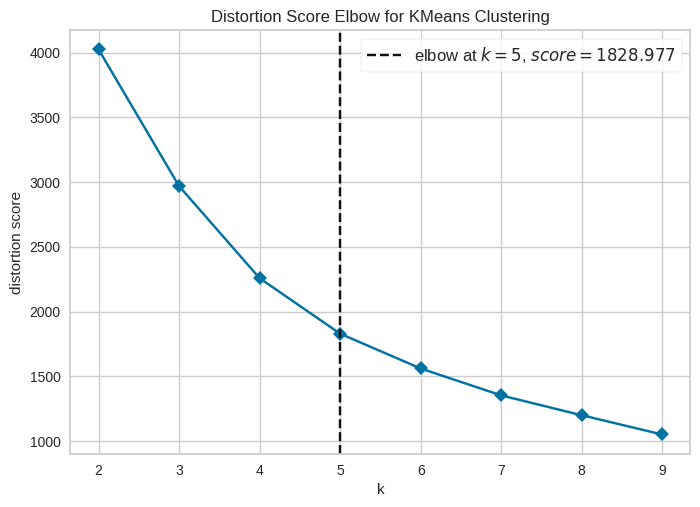

Оптимальна кількість кластерів після PCA: 5


In [ ]:
model = KMeans(
    random_state=42,
    n_init=10
)

visualizer = KElbowVisualizer(
    model,
    k=(2, 10),
    metric='distortion',
    timings=False
)

visualizer.fit(X_pca_final)

visualizer.show()

print("Оптимальна кількість кластерів після PCA:",
      visualizer.elbow_value_)

## Висновки

Порівняйте результати різних способів визначення кількості кластерів та сформулюйте короткі висновки. Для завдання 2 окремо поясніть різницю між класифікацією за `GradeClass` і кластеризацією без цільової змінної. Зазначте, скільки головних компонент обрано та яку частку дисперсії вони пояснюють.

Під час лабораторної роботи було досліджено алгоритм K-Means, метод ліктя, коефіцієнт силуета та PCA.

Для визначення оптимальної кількості кластерів використовувалися різні методи, результати яких порівнювалися між собою. Вони допомагають оцінити якість групування даних за різними критеріями.

У другому завданні було виконано класифікацію студентів за GradeClass за допомогою Random Forest, Logistic Regression та SVM. На відміну від класифікації, кластеризація не використовує цільову змінну, а самостійно групує студентів за схожістю характеристик.

За допомогою PCA було зменшено розмірність даних до [N] компонент, які пояснюють [X]% дисперсії.